# Évaluation sommative 2 : Création des pipelines
## Prédiction des annulations de réservations hôtelières (Hotel Booking Demand)

**Cours :** Intelligence artificielle appliquée au prétraitement des données (030513 IFM), automne 2026
**Professeure :** Nadjate Saïdani
**Étudiant :** Yacine Lezoul
**Date :** 11 novembre 2026

---

### Objectif
Construire un pipeline scikit-learn complet qui enchaîne le prétraitement des données, des transformateurs personnalisés, la sélection des caractéristiques et un modèle de classification, pour prédire si une réservation sera annulée (`is_canceled`).

### Où se trouve le code
Les pipelines et les transformateurs sont écrits dans des scripts Python (dossier `src/`), puis **importés** dans ce notebook, qui sert à les exécuter, à présenter les résultats et à les interpréter. Le code importé est affiché dans le notebook au moment où il est utilisé.

| Fichier | Contenu | Utilisé en |
|---|---|---|
| `src/data_loader.py` | chargement, diagnostic de qualité, nettoyage, séparation 80/20 | Partie 1 |
| `src/pipelines.py` | **tous les pipelines** : `pipeline_continu`, `pipeline_discret`, `pipeline_binaire`, `pipeline_cat`, `preprocessor` (ColumnTransformer), `pipeline_pretraitement`, `selecteur`, `model_pipeline` | Parties 2, 4 et 5 |
| `src/transformers.py` | transformateurs personnalisés (`TransformerMixin`) : `HotelFeatureEngineer`, `RareCategoryGrouper`, `OutlierCapper` | Partie 3 |
| `src/evaluation.py` | métriques, scorer F2, graphiques, bilan de la sélection | Parties 4 et 5 |
| `src/sauvegarde.py` | enregistrement du pipeline entraîné | Partie 5 |
| `src/config.py` | chemins, colonnes de fuite, graine aléatoire | partout |

L'analyse prescriptive (pertes, revente des chambres, acomptes) est dans un second notebook : `02_analyse_prescriptive.ipynb`.

### Plan
1. Exploration et préparation des données
2. Construction des pipelines de prétraitement
3. Création de transformateurs personnalisés
4. Sélection des caractéristiques
5. Construction et évaluation du modèle prédictif

In [1]:
# ---------------------------------------------------------------
# Configuration de l'environnement
# ---------------------------------------------------------------
import sys
import warnings
from pathlib import Path

# Le notebook est dans notebooks/ : on ajoute la racine du projet au chemin
# pour pouvoir importer les scripts du dossier src/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore")  # masque les avertissements de version des bibliothèques

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn import set_config

# Sortie pandas : chaque étape des pipelines renvoie un DataFrame avec des noms de colonnes.
# display="text" : les pipelines s'affichent en texte (notebook léger, ouverture rapide).
set_config(transform_output="pandas", display="text")

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", palette="deep")

from src import config
from src import data_loader as dl

from typing import TypeVar, cast

from sklearn.base import clone

T = TypeVar("T")


def copie(objet: T) -> T:
    """copie() de scikit-learn : copie NON entraînée d'un pipeline ou d'un modèle.

    Le type est simplement précisé pour l'éditeur (VS Code), qui ne sait pas
    que copie() renvoie un objet du même type que celui qu'on lui donne.
    """
    return cast(T, clone(objet))


def afficher_code(debut: str, fin: str | None = None, fichier: str = "src/pipelines.py") -> None:
    """Affiche la partie d'un script comprise entre deux lignes repères (fin=None : jusqu'au bout)."""
    lignes = (ROOT / fichier).read_text(encoding="utf-8").splitlines()
    i = next(k for k, l in enumerate(lignes) if debut in l)
    j = len(lignes) if fin is None else next(k for k, l in enumerate(lignes) if fin in l and k > i)
    print(f"# ----- Extrait de {fichier} -----")
    print("\n".join(lignes[i:j]))

---
# Partie 1 : Exploration et préparation des données

## 1.1 Importation et structure générale
Fonction utilisée : `load_raw_data()` de `src/data_loader.py`. Les valeurs `NULL` des colonnes `agent` et `company` sont lues comme des valeurs manquantes.

In [2]:
df_raw = dl.load_raw_data()  # télécharge le fichier s'il est absent de data/raw/
print(f"Dimensions : {df_raw.shape[0]} lignes x {df_raw.shape[1]} colonnes")
df_raw.head()

Dimensions : 119390 lignes x 32 colonnes


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df_raw.info()  # types et nombre de valeurs non manquantes par colonne

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
df_raw.describe().T.round(2)  # statistiques descriptives des colonnes numériques

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


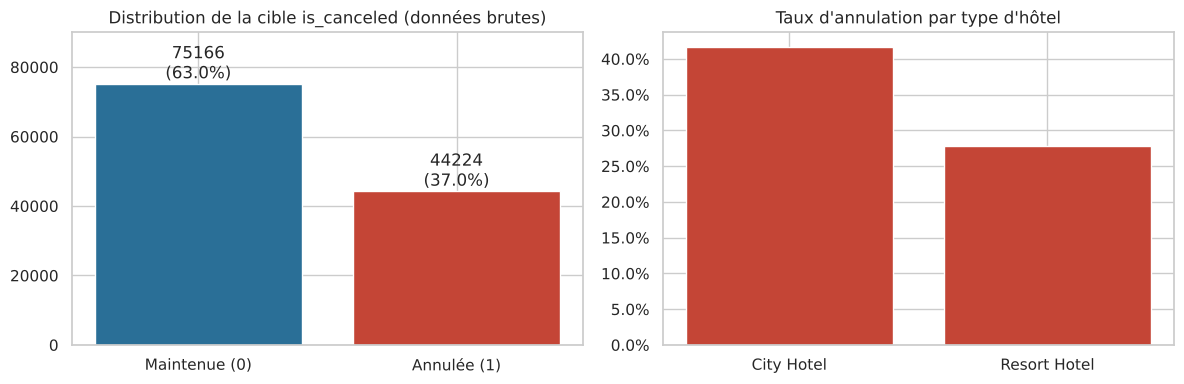

In [5]:
# Distribution de la cible et taux d'annulation par hôtel
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

counts = df_raw[config.TARGET].value_counts().sort_index()
ax[0].bar(["Maintenue (0)", "Annulée (1)"], counts.values, color=["#2a6f97", "#c44536"])
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax[0].set_title("Distribution de la cible is_canceled (données brutes)")
ax[0].set_ylim(0, counts.max() * 1.2)

rate = df_raw.groupby("hotel")[config.TARGET].mean()
ax[1].bar(rate.index, rate.values, color="#c44536")
ax[1].set_title("Taux d'annulation par type d'hôtel")
ax[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

**Interprétation :** le jeu brut compte 119 390 réservations et 32 colonnes. La cible est **déséquilibrée sans être extrême** : 37 % d'annulations dans les données brutes. Le City Hotel annule nettement plus (41,7 %) que le Resort Hotel (27,8 %) : le type d'hôtel sera une variable explicative utile.

## 1.2 Variables numériques, catégorielles et problèmes de qualité

### Typologie des variables

In [6]:
num_cols = df_raw.select_dtypes(include="number").columns.drop(config.TARGET).tolist()
cat_cols = df_raw.select_dtypes(exclude="number").columns.tolist()
print(f"Variables numériques ({len(num_cols)}) :", num_cols, "\n")
print(f"Variables catégorielles ({len(cat_cols)}) :", cat_cols)

Variables numériques (19) : ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests'] 

Variables catégorielles (12) : ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


**Attention aux faux numériques :** `agent` et `company` sont stockés comme des nombres mais ce sont des **identifiants** (aucun ordre, aucune distance). `is_repeated_guest` est un indicateur binaire. Le type informatique ne suffit donc pas : chaque variable est traitée selon sa **nature** (Partie 2).

### Valeurs manquantes et cardinalité (fonction `quality_report()`)

In [7]:
dl.quality_report(df_raw).head(12)

,type,manquants,manquants_%,valeurs_uniques
company,float64,112593,94.31,352
agent,float64,16340,13.69,333
country,str,488,0.41,177
hotel,str,0,0.00,2
arrival_date_month,str,0,0.00,12
arrival_date_week_number,int64,0,0.00,53
lead_time,int64,0,0.00,479
is_canceled,int64,0,0.00,2
stays_in_weekend_nights,int64,0,0.00,17
stays_in_week_nights,int64,0,0.00,35


### Anomalies détectées (fonction `quality_issues()`)

In [8]:
dl.quality_issues(df_raw).to_frame()

,nombre de lignes
lignes en double,31994
"réservations sans aucun client (0 adulte, 0 enfant, 0 bébé)",180
adr négatif,1
adr aberrant (> 1 000),1
séjours de 0 nuit,715
meal = 'Undefined' (équivaut à SC selon la fiche),1169
market_segment = 'Undefined',2
distribution_channel = 'Undefined',5
children manquant,4
country manquant,488


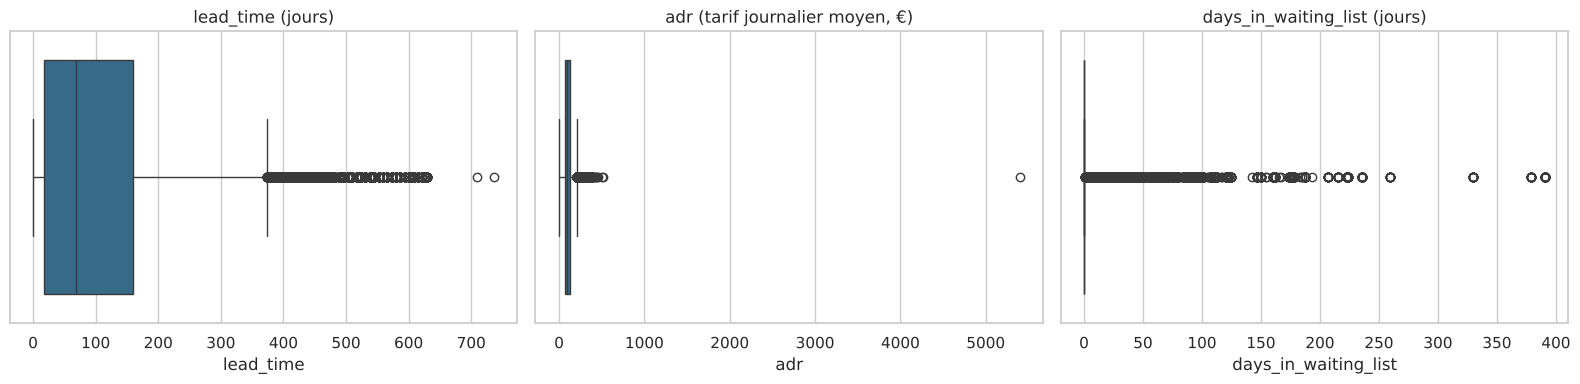

In [9]:
# Valeurs extrêmes des principales variables continues
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, titre in zip(
    axes,
    ["lead_time", "adr", "days_in_waiting_list"],
    ["lead_time (jours)", "adr (tarif journalier moyen, €)", "days_in_waiting_list (jours)"],
):
    sns.boxplot(x=df_raw[col], ax=ax, color="#2a6f97")
    ax.set_title(titre)
plt.tight_layout()
plt.show()

In [10]:
# Cardinalité de country
pays = df_raw["country"].value_counts()
print(f"Nombre de pays : {pays.size}")
print(f"Pays représentant moins de 0,5 % des réservations : {(pays / len(df_raw) < 0.005).sum()}")
pays.head(10).to_frame("réservations")

Nombre de pays : 177
Pays représentant moins de 0,5 % des réservations : 157


,réservations
country,
PRT,48590
GBR,12129
FRA,10415
ESP,8568
DEU,7287
ITA,3766
IRL,3375
BEL,2342
BRA,2224


**Interprétation :** plusieurs problèmes de qualité sont à traiter.

- **Valeurs manquantes** : `company` (94 %) et `agent` (14 %) ne sont pas de vraies absences, elles signifient « pas d'entreprise » et « pas d'agence ». `country` (488 lignes) et `children` (4 lignes) sont de vraies données manquantes.
- **Doublons** : 31 994 lignes strictement identiques (27 %).
- **Valeurs impossibles** : 180 réservations sans aucun client, un tarif négatif, un tarif de 5 400 €.
- **Modalités ambiguës** : `meal = Undefined` (équivalent de SC selon la fiche), `market_segment` et `distribution_channel = Undefined`.
- **Valeurs extrêmes et asymétrie** : `lead_time` jusqu'à 737 jours, `days_in_waiting_list` jusqu'à 391 jours, `adr` avec une longue queue.
- **Forte cardinalité** : 177 pays, dont 157 pèsent chacun moins de 0,5 % des réservations.

### Détection d'une fuite de données (data leakage)
Certaines colonnes ne sont connues **qu'après** l'issue de la réservation. On croise `reservation_status` avec la cible :

In [11]:
pd.crosstab(df_raw["reservation_status"], df_raw[config.TARGET], margins=True, margins_name="Total")

is_canceled,0,1,Total
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
Total,75166,44224,119390


In [12]:
# assigned_room_type : la chambre est attribuée à l'arrivée du client
chambre_differente = df_raw["reserved_room_type"] != df_raw["assigned_room_type"]
(
    df_raw.groupby(chambre_differente)[config.TARGET].mean()
    .rename(index={False: "même chambre", True: "chambre différente"})
    .to_frame("taux d'annulation")
)

,taux d'annulation
même chambre,0.415629
chambre différente,0.053764


**Interprétation :** `reservation_status` reproduit exactement la cible (Canceled et No-Show = 1, Check-Out = 0) : la garder donnerait un modèle « parfait » mais inutilisable, car ce statut n'existe qu'après coup. De même, une chambre attribuée différente de la chambre réservée s'accompagne de 5,4 % d'annulations seulement, contre 41,6 % sinon : la chambre est attribuée à l'arrivée, ce qui révèle que le client est venu. `reservation_status`, `reservation_status_date` et `assigned_room_type` sont donc exclues des variables explicatives.

### Relations exploratoires avec la cible

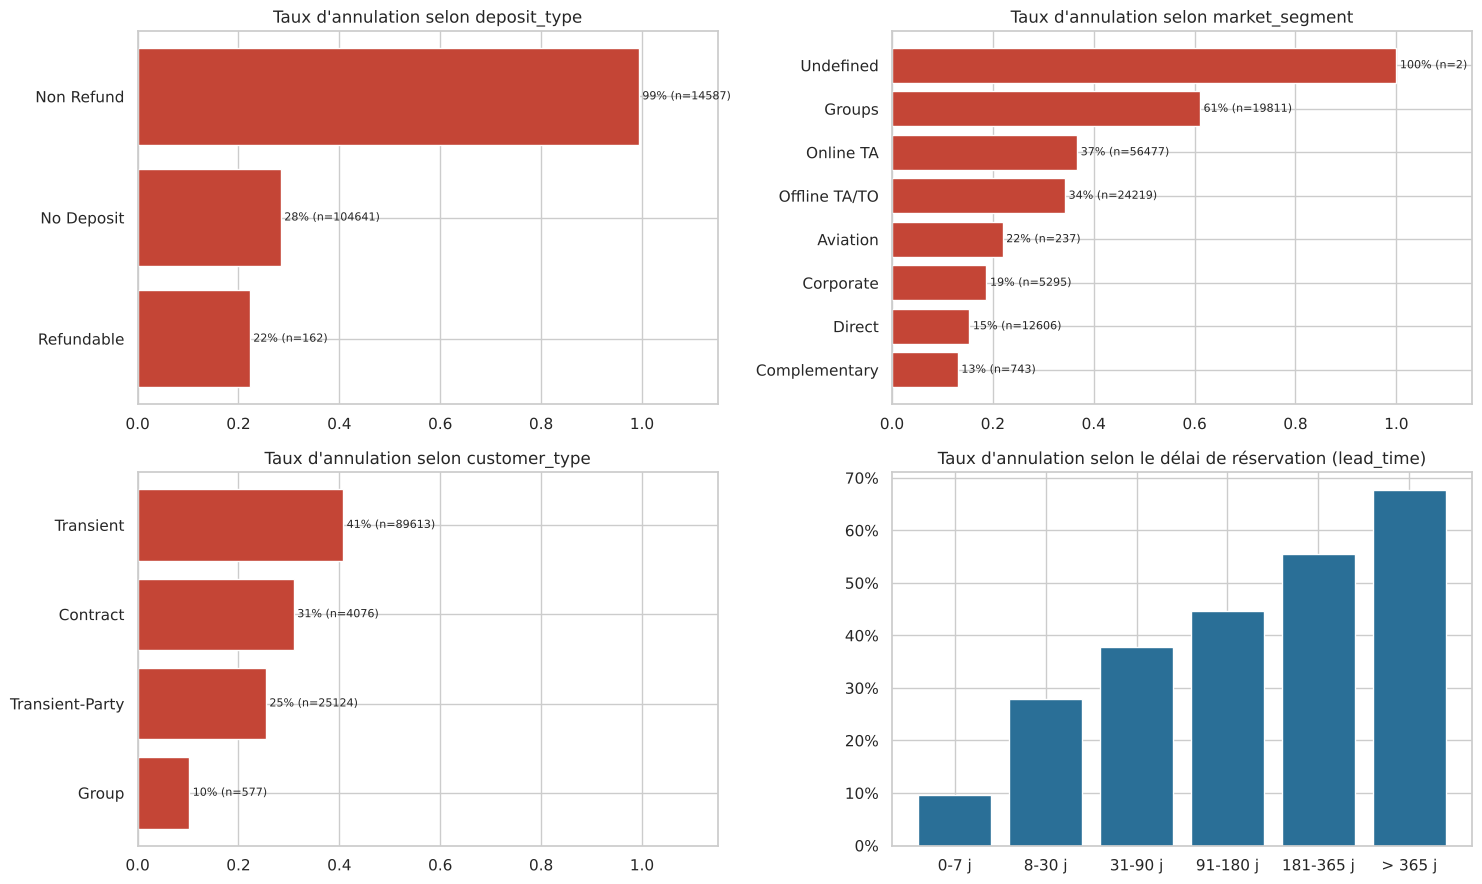

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Taux d'annulation selon trois variables catégorielles
for ax, col in zip(axes.flat[:3], ["deposit_type", "market_segment", "customer_type"]):
    r = df_raw.groupby(col)[config.TARGET].agg(["mean", "size"]).sort_values("mean")
    ax.barh(r.index, r["mean"], color="#c44536")
    for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(m, i, f" {m:.0%} (n={n})", va="center", fontsize=8)
    ax.set_title(f"Taux d'annulation selon {col}")
    ax.set_xlim(0, 1.15)

# Taux d'annulation selon le délai de réservation
bins = [-1, 7, 30, 90, 180, 365, 800]
labels = ["0-7 j", "8-30 j", "31-90 j", "91-180 j", "181-365 j", "> 365 j"]
r = df_raw.groupby(pd.cut(df_raw["lead_time"], bins=bins, labels=labels), observed=True)[config.TARGET].mean()
axes[1, 1].bar(r.index.astype(str), r.values, color="#2a6f97")
axes[1, 1].set_title("Taux d'annulation selon le délai de réservation (lead_time)")
axes[1, 1].yaxis.set_major_formatter(PercentFormatter(1))

plt.tight_layout()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(config.FIGURES_DIR / "exploration_taux_annulation.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :**

- **Délai de réservation** : relation nette et croissante, de 10 % d'annulations à moins d'une semaine à 68 % au-delà d'un an.
- **Segment de marché** : les groupes (61 %) et les agences en ligne (37 %) annulent beaucoup plus que la clientèle directe (15 %) ou d'entreprise (19 %).
- **Type de dépôt** : les réservations non remboursables annulent à 99 %, ce qui est contre-intuitif. Il s'agit surtout de blocs de réservations d'agences (analyse détaillée dans le notebook 02). La variable est conservée car elle est connue au moment de la réservation.
- **Type de client** : les clients individuels (*Transient*, 41 %) annulent plus que les groupes sous contrat.

### Nettoyage de base (fonction `clean_data()`)

**Règle suivie dans tout le projet :** tout ce qui doit s'appliquer à une **nouvelle réservation** est fait **dans le pipeline** ; ce qui **supprime des lignes** de l'historique est fait **une seule fois, avant** la séparation entraînement / test.

| Opération | Où | Pourquoi |
|---|---|---|
| Retrait de `reservation_status`, `reservation_status_date`, `assigned_room_type` | ici | fuite de données (le `ColumnTransformer` les ignorerait aussi, car il ne garde que les colonnes listées) |
| Suppression de 33 241 doublons exacts | ici | sans identifiant de réservation, une même ligne pourrait être à la fois dans l'entraînement et dans le test |
| Suppression des réservations sans client et des tarifs impossibles | ici | erreurs de saisie |
| Valeurs manquantes, « Undefined », valeurs extrêmes, encodage | **pipeline** | doivent s'appliquer à chaque nouvelle réservation, avec des paramètres appris sur l'entraînement |

Pourquoi la suppression de lignes ne peut pas être une étape du pipeline : dans un `Pipeline`, `transform()` reçoit seulement `X`. Une étape qui retirerait des lignes de `X` désalignerait `X` et `y`. De plus, les doublons doivent être retirés **avant** la séparation 80/20, que le pipeline ne voit pas.

In [14]:
df = dl.clean_data(df_raw)
print(f"\nTaux d'annulation après nettoyage : {df[config.TARGET].mean():.1%}")

Lignes initiales                     : 119 390
Doublons supprimés                   :  33 241
Réservations sans client supprimées  :     165
Tarifs impossibles supprimés         :       2
Lignes finales                       :  85 982

Taux d'annulation après nettoyage : 27.6%


**Interprétation :** il reste **85 982 réservations**. On compte 33 241 doublons, un peu plus que les 31 994 du diagnostic : une fois les colonnes de fuite écartées, des lignes qui ne différaient que par la date de statut deviennent identiques. Le taux d'annulation passe de 37 % à **27,6 %** : les doublons étaient surtout des annulations (blocs de réservations de groupes annulés ensemble).

## 1.3 Variables explicatives et variable cible
- **Cible `y`** : `is_canceled` (1 = annulée, 0 = maintenue). Problème de **classification binaire**.
- **Variables explicatives `X`** : les 27 informations disponibles **au moment de la réservation** (liste `config.RAW_INPUT_FEATURES`).

`arrival_date_year` (2015 à 2017) est exclue : le modèle servira sur des années futures qu'il n'a jamais vues.

In [15]:
X, y = dl.split_features_target(df)
print(f"X : {X.shape}, y : {y.shape}")
print("Colonnes non utilisées comme variables explicatives :", sorted(set(df.columns) - set(X.columns) - {config.TARGET}))
X.head(3)

X : (85982, 27), y : (85982,)
Colonnes non utilisées comme variables explicatives : ['arrival_date_year']


,hotel,lead_time,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,342,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0
1,Resort Hotel,737,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0
2,Resort Hotel,7,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0


## 1.4 Séparation entraînement (80 %) / test (20 %)
Séparation **stratifiée** (même taux d'annulation dans les deux ensembles) avec `random_state` fixé. L'ensemble de test n'est plus utilisé avant l'évaluation finale : toutes les décisions (choix du modèle, hyperparamètres, seuil) sont prises par validation croisée **à l'intérieur** de l'entraînement.

In [16]:
X_train, X_test, y_train, y_test = dl.train_test_data(X, y)
pd.DataFrame(
    {
        "lignes": [len(X_train), len(X_test)],
        "part": [len(X_train) / len(X), len(X_test) / len(X)],
        "taux d'annulation": [y_train.mean(), y_test.mean()],
    },
    index=["entraînement", "test"],
).round(3)

,lignes,part,taux d'annulation
entraînement,68785,0.8,0.276
test,17197,0.2,0.276


---
# Partie 2 : Construction des pipelines de prétraitement

## 2.1 Traitements retenus par type de variable

| Groupe | Variables | Traitements | Justification |
|---|---|---|---|
| **Continues** | `lead_time`, `adr`, nuits, `total_nights`, `adr_per_person` | médiane, écrêtage 1 % / 99 %, standardisation | distributions très asymétriques avec valeurs extrêmes (737 jours de délai) ; la médiane résiste aux extrêmes ; l'écrêtage évite qu'ils dominent la standardisation |
| **Discrètes** | comptages (clients, annulations passées, modifications, demandes, jours d'attente) et calendrier | médiane, standardisation | pas d'écrêtage : le 99e centile vaut souvent 0 ou 1 (plus de 99 % des réservations n'ont aucun jour d'attente), l'écrêtage effacerait des profils rares mais informatifs |
| **Binaires** | `is_repeated_guest`, `has_children`, `has_agent`, `has_company` | valeur la plus fréquente | déjà en 0/1, la mise à l'échelle n'apporte rien |
| **Catégorielles** | hôtel, mois, saison, repas, pays, segment, canal, chambre, dépôt, type de client | constante « Inconnu », regroupement des rares, one-hot | aucune relation d'ordre ; l'absence de pays est une information ; `handle_unknown="ignore"` protège la prédiction face à une modalité nouvelle |

## 2.2 Pipelines par type de variable
Les pipelines sont écrits dans **`src/pipelines.py`**, sur le modèle du cours (« Préparation de pipelines spécifiques »). Voici le code importé :

In [17]:
afficher_code("# 0. Colonnes à traiter", "# 2. Combine les traitements")

# ----- Extrait de src/pipelines.py -----
# 0. Colonnes à traiter
#    (après HotelFeatureEngineer, qui crée total_nights, total_guests,
#     adr_per_person, has_children, has_agent, has_company, arrival_season)
# ===========================================================================

# Variables continues très asymétriques : imputation, écrêtage, standardisation
colonnes_continues = [
    "lead_time",                 # délai entre réservation et arrivée (jusqu'à 737 jours)
    "adr",                       # tarif journalier moyen
    "stays_in_weekend_nights",   # nuits de fin de semaine
    "stays_in_week_nights",      # nuits de semaine
    "total_nights",              # créée : nuits totales
    "adr_per_person",            # créée : tarif par personne
]

# Variables discrètes (comptages, calendrier) : imputation, standardisation.
# Pas d'écrêtage : pour ces comptages, le 99e centile vaut souvent 0 ou 1 et
# l'écrêtage effacerait des profils rares mais informatifs.
colonnes_d

In [18]:
# Import des pipelines depuis src/pipelines.py
from src.pipelines import (
    colonnes_binaires, colonnes_cat, colonnes_continues, colonnes_discretes,
    pipeline_binaire, pipeline_cat, pipeline_continu, pipeline_discret,
)

# Chaque pipeline est une liste ordonnée de couples (nom de l'étape, transformateur)
for nom, pipe in [("pipeline_continu", pipeline_continu), ("pipeline_discret", pipeline_discret),
                  ("pipeline_binaire", pipeline_binaire), ("pipeline_cat", pipeline_cat)]:
    print(f"{nom:<17}:", " -> ".join(f"{etape} ({type(t).__name__})" for etape, t in pipe.steps))

pipeline_continu : imputation (SimpleImputer) -> ecretage (OutlierCapper) -> scaling (StandardScaler)
pipeline_discret : imputation (SimpleImputer) -> scaling (StandardScaler)
pipeline_binaire : imputation (SimpleImputer)
pipeline_cat     : imputation (SimpleImputer) -> regroupement_rares (RareCategoryGrouper) -> encoding (OneHotEncoder)


## 2.3 ColumnTransformer : chaque groupe de colonnes reçoit son pipeline
Toujours dans `src/pipelines.py` (cours : « Combine les traitements dans un seul objet ») :

In [19]:
afficher_code("# 2. Combine les traitements", "# 4. Sélection des caractéristiques")

# ----- Extrait de src/pipelines.py -----
# 2. Combine les traitements dans un seul objet (ColumnTransformer)
# ===========================================================================
preprocessor = ColumnTransformer([
    ("num_continu", pipeline_continu, colonnes_continues),
    ("num_discret", pipeline_discret, colonnes_discretes),
    ("binaire", pipeline_binaire, colonnes_binaires),
    ("cat", pipeline_cat, colonnes_cat),
], remainder="drop")  # toute colonne non listée est écartée

# ===========================================================================
# 3. Pipeline de prétraitement complet
#    Le transformateur personnalisé HotelFeatureEngineer crée d'abord les
#    nouvelles variables ; le ColumnTransformer les route ensuite vers le bon
#    sous-pipeline. L'ordre des étapes est donc essentiel.
# ===========================================================================
pipeline_pretraitement = Pipeline([
    ("creation_variables", HotelFeatureEngineer()),  # Parti

In [20]:
from src.pipelines import pipeline_pretraitement, preprocessor

preprocessor  # ColumnTransformer : 4 sous-pipelines appliqués chacun à ses colonnes

ColumnTransformer(transformers=[('num_continu',
                                 Pipeline(steps=[('imputation',
                                                  SimpleImputer(strategy='median')),
                                                 ('ecretage', OutlierCapper()),
                                                 ('scaling',
                                                  StandardScaler())]),
                                 ['lead_time', 'adr', 'stays_in_weekend_nights',
                                  'stays_in_week_nights', 'total_nights',
                                  'adr_per_person']),
                                ('num_discret',
                                 Pipeline(steps=[('imputation',
                                                  SimpleImputer(strategy='median')...
                                 Pipeline(steps=[('imputation',
                                                  SimpleImputer(fill_value='Inconnu',
                                  

In [21]:
pipeline_pretraitement  # HotelFeatureEngineer (Partie 3) puis le ColumnTransformer

Pipeline(steps=[('creation_variables', HotelFeatureEngineer()),
                ('colonnes',
                 ColumnTransformer(transformers=[('num_continu',
                                                  Pipeline(steps=[('imputation',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('ecretage',
                                                                   OutlierCapper()),
                                                                  ('scaling',
                                                                   StandardScaler())]),
                                                  ['lead_time', 'adr',
                                                   'stays_in_weekend_nights',
                                                   'stays_in_week_nights',
                                                   'total_nights',
                                      

## 2.4 Résultat du prétraitement
Comme dans le cours : `fit_transform()` sur l'entraînement (apprentissage des médianes, bornes, modalités, moyennes et écarts-types), puis `transform()` sur le test (application des mêmes paramètres, sans réapprendre).

In [22]:
# copie() : copie non entraînée, pour garder intact l'objet importé de src/pipelines.py
pretraitement = copie(pipeline_pretraitement)

# pd.DataFrame(...) : la sortie est déjà un DataFrame (set_output pandas) ; l'appel rend le type explicite
X_train_prep = pd.DataFrame(pretraitement.fit_transform(X_train))  # apprend ET transforme
X_test_prep = pd.DataFrame(pretraitement.transform(X_test))        # transforme seulement

print(f"Avant prétraitement : {X_train.shape[1]} colonnes brutes")
print(f"Après prétraitement : {X_train_prep.shape[1]} colonnes numériques")
print(f"Valeurs manquantes restantes (entraînement / test) : "
      f"{X_train_prep.isna().sum().sum()} / {X_test_prep.isna().sum().sum()}")
X_train_prep.head()

Avant prétraitement : 27 colonnes brutes
Après prétraitement : 93 colonnes numériques
Valeurs manquantes restantes (entraînement / test) : 0 / 0


,num_continu__lead_time,num_continu__adr,num_continu__stays_in_weekend_nights,num_continu__stays_in_week_nights,num_continu__total_nights,num_continu__adr_per_person,num_discret__days_in_waiting_list,num_discret__arrival_date_week_number,num_discret__arrival_date_day_of_month,num_discret__adults,num_discret__children,num_discret__babies,num_discret__previous_cancellations,num_discret__previous_bookings_not_canceled,num_discret__booking_changes,num_discret__required_car_parking_spaces,num_discret__total_of_special_requests,num_discret__total_guests,binaire__is_repeated_guest,binaire__has_children,binaire__has_agent,binaire__has_company,cat__hotel_City Hotel,cat__hotel_Resort Hotel,cat__arrival_date_month_April,cat__arrival_date_month_August,cat__arrival_date_month_December,cat__arrival_date_month_February,cat__arrival_date_month_January,cat__arrival_date_month_July,...,cat__market_segment_Complementary,cat__market_segment_Corporate,cat__market_segment_Direct,cat__market_segment_Groups,cat__market_segment_Offline TA/TO,cat__market_segment_Online TA,cat__distribution_channel_Autre,cat__distribution_channel_Corporate,cat__distribution_channel_Direct,cat__distribution_channel_TA/TO,cat__reserved_room_type_A,cat__reserved_room_type_Autre,cat__reserved_room_type_B,cat__reserved_room_type_C,cat__reserved_room_type_D,cat__reserved_room_type_E,cat__reserved_room_type_F,cat__reserved_room_type_G,cat__reserved_room_type_H,cat__deposit_type_Autre,cat__deposit_type_No Deposit,cat__deposit_type_Non Refund,cat__customer_type_Contract,cat__customer_type_Group,cat__customer_type_Transient,cat__customer_type_Transient-Party,cat__arrival_season_Automne,cat__arrival_season_Ete,cat__arrival_season_Hiver,cat__arrival_season_Printemps
74199,-0.896850,-0.968723,-0.000222,-0.319397,-0.242621,0.063912,-0.070392,-1.667095,1.265108,-1.400601,-0.305112,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,-0.846662,-1.294837,0,0,1,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
17309,-0.944978,-1.244588,-0.000222,-1.374035,-1.034153,-0.452993,-0.070392,-1.082124,-0.203910,-1.400601,-0.305112,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,-0.846662,-1.294837,0,0,1,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
17689,-0.668243,-0.950280,1.016470,0.207923,0.548912,-0.967692,-0.070392,-1.082124,0.361097,0.188177,-0.305112,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,0.353768,-0.040660,0,0,1,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
59540,-0.078679,-0.137009,-1.016913,0.735242,0.153145,-0.205753,-0.070392,-0.789639,-0.429913,0.188177,-0.305112,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,0.353768,-0.040660,0,0,1,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
32606,0.919971,3.062433,1.016470,1.262561,1.340444,0.429349,-0.070392,0.307181,1.717114,0.188177,4.060846,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,2.754629,2.467692,0,1,1,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [23]:
# Nombre de colonnes produites par chaque branche du ColumnTransformer
branches = pd.Series([c.split("__")[0] for c in X_train_prep.columns]).value_counts()
branches.to_frame("colonnes")

,colonnes
cat,71
num_discret,12
num_continu,6
binaire,4


In [24]:
# Vérification : les variables standardisées ont une moyenne de 0 et un écart-type de 1
standardisees = [c for c in X_train_prep.columns if c.startswith(("num_continu__", "num_discret__"))]
X_train_prep[standardisees].describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
num_continu__lead_time,0.0,1.0,-0.945,3.182
num_continu__adr,-0.0,1.0,-2.088,3.062
num_continu__stays_in_weekend_nights,-0.0,1.0,-1.017,3.050
num_continu__stays_in_week_nights,-0.0,1.0,-1.374,3.899
num_continu__total_nights,-0.0,1.0,-1.034,4.111
num_continu__adr_per_person,0.0,1.0,-2.034,3.482
num_discret__days_in_waiting_list,-0.0,1.0,-0.070,43.090
num_discret__arrival_date_week_number,-0.0,1.0,-1.886,1.916
num_discret__arrival_date_day_of_month,0.0,1.0,-1.673,1.717
num_discret__adults,-0.0,1.0,-2.989,84.393


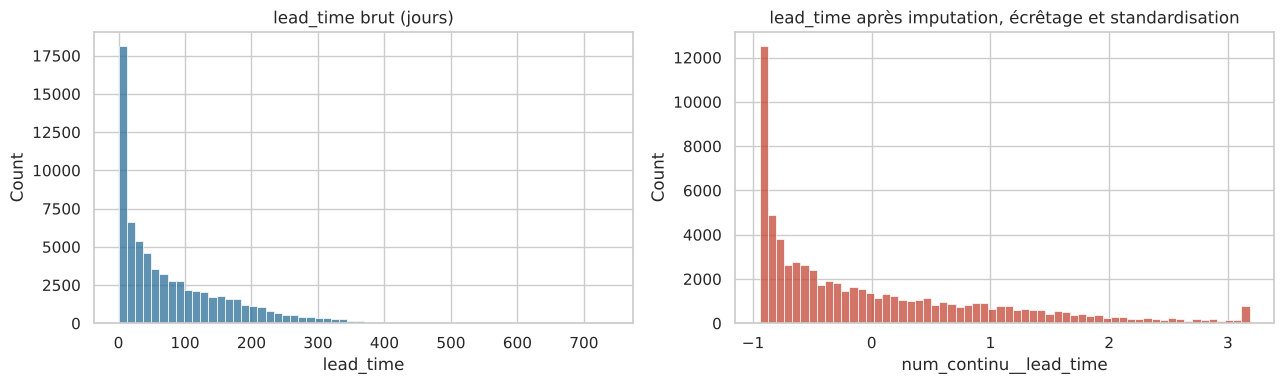

In [25]:
# Effet du prétraitement sur lead_time
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(x=X_train["lead_time"], bins=60, ax=axes[0], color="#2a6f97")
axes[0].set_title("lead_time brut (jours)")
sns.histplot(x=X_train_prep["num_continu__lead_time"], bins=60, ax=axes[1], color="#c44536")
axes[1].set_title("lead_time après imputation, écrêtage et standardisation")
plt.tight_layout()
plt.show()

**Interprétation :** les 27 variables brutes deviennent **93 colonnes numériques sans aucune valeur manquante**, dans l'entraînement comme dans le test : 6 continues, 12 discrètes, 4 binaires et 71 indicatrices issues de l'encodage one-hot. Les variables standardisées ont bien une moyenne de 0 et un écart-type de 1. L'effet de l'écrêtage est visible sur `lead_time` : la queue au-delà de 343 jours est ramenée à la borne, et le maximum standardisé n'est plus que de 3,2. À l'inverse, `adults` et `days_in_waiting_list`, volontairement non écrêtées, gardent des maximums élevés (84 et 43 écarts-types), qui correspondent à des réservations de groupes réelles. Le pipeline a été ajusté sur l'entraînement seulement (`fit_transform`), puis appliqué au test (`transform`) : aucune information du test n'a servi à calculer les médianes, bornes ou moyennes.

---
# Partie 3 : Création de transformateurs personnalisés

## 3.1 Variables nécessitant un traitement spécifique

| Problème observé | Variables | Transformateur |
|---|---|---|
| Information dispersée sur plusieurs colonnes | nuits, adultes, enfants, bébés, tarif | `HotelFeatureEngineer` : `total_nights`, `total_guests`, `adr_per_person`, `has_children` |
| Identifiants sans ordre, 94 % de manquants pour `company` | `agent`, `company` | `HotelFeatureEngineer` : `has_agent`, `has_company`, puis retrait des identifiants |
| Saisonnalité | `arrival_date_month` | `HotelFeatureEngineer` : `arrival_season` |
| Modalités « Undefined » | `meal`, `market_segment`, `distribution_channel` | `HotelFeatureEngineer` : `meal` Undefined = SC, les autres deviennent manquants |
| Très forte cardinalité | `country` (177 pays) | `RareCategoryGrouper` : modalités < 0,5 % regroupées dans « Autre » |
| Valeurs extrêmes | `lead_time`, `adr`, nuits | `OutlierCapper` : écrêtage aux 1er et 99e centiles |

## 3.2 et 3.3 Classes développées avec `TransformerMixin`
Les classes sont dans **`src/transformers.py`**. Elles suivent le modèle du cours (`NormaliseurMinMax`) :

| Écrit à la main | Fourni par scikit-learn |
|---|---|
| `__init__` : mémorise les paramètres | `TransformerMixin` : `fit_transform()` |
| `fit()` : apprend sur l'entraînement, retourne `self` | `BaseEstimator` : `get_params()`, `set_params()` (nécessaires à `clone` et à la validation croisée) |
| `transform()` : copie X, applique la règle | `OneToOneFeatureMixin` : `get_feature_names_out()` pour les transformateurs qui gardent les mêmes colonnes |
| | `validate_data()` : enregistre les noms des colonnes d'entrée |

Seule exception : `HotelFeatureEngineer` **crée** des colonnes, dont scikit-learn ne peut pas deviner les noms ; son `get_feature_names_out()` est donc écrit à la main. Ces noms sont indispensables pour savoir, en Partie 4, quelles variables sont retenues.

In [26]:
import inspect

from src.transformers import HotelFeatureEngineer, OutlierCapper, RareCategoryGrouper

# Affichage du code de chaque classe importée de src/transformers.py
for classe in (HotelFeatureEngineer, RareCategoryGrouper, OutlierCapper):
    print(inspect.getsource(classe))

class HotelFeatureEngineer(TransformerMixin, BaseEstimator):
    """Crée des variables métier et corrige les modalités « Undefined ».

    Variables créées
        total_nights    = nuits de semaine + nuits de fin de semaine
        total_guests    = adultes + enfants + bébés
        adr_per_person  = tarif journalier / nombre de clients
        has_children    = 1 si au moins un enfant ou un bébé
        has_agent       = 1 si réservation via une agence (agent renseigné)
        has_company     = 1 si séjour payé par une entreprise (company renseigné)
        arrival_season  = saison déduite du mois d'arrivée
    Corrections
        meal « Undefined » -> « SC » (équivalents selon la fiche des données)
        market_segment, distribution_channel « Undefined » -> valeur manquante
    Colonnes retirées
        agent, company : identifiants sans ordre ; seule leur présence compte

    Comme SalaireAnnuel dans le cours, fit() n'apprend aucune statistique :
    la règle est fixe.
    """



### Démonstration de `HotelFeatureEngineer`

In [27]:
fe = HotelFeatureEngineer().fit(X_train)  # fit() n'apprend aucune statistique : la règle est fixe
demo = X_train.head(5)

avant = demo[["stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
              "adr", "agent", "company", "arrival_date_month", "meal"]]
apres = pd.DataFrame(fe.transform(demo))[["total_nights", "total_guests", "adr_per_person", "has_children",
                                          "has_agent", "has_company", "arrival_season", "meal"]]
display(avant)
display(apres)

,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr,agent,company,arrival_date_month,meal
74199,1,2,1,0.0,0,57.06,7.0,NaN,January,SC
17309,1,0,1,0.0,0,43.00,240.0,NaN,March,BB
17689,2,3,2,0.0,0,58.00,196.0,NaN,March,HB
59540,0,4,2,0.0,0,99.45,9.0,NaN,April,BB
32606,2,5,2,2.0,0,268.00,240.0,NaN,July,HB


,total_nights,total_guests,adr_per_person,has_children,has_agent,has_company,arrival_season,meal
74199,3,1.0,57.060,0,1,0,Hiver,SC
17309,1,1.0,43.000,0,1,0,Printemps,BB
17689,5,2.0,29.000,0,1,0,Printemps,HB
59540,4,2.0,49.725,0,1,0,Printemps,BB
32606,7,4.0,67.000,1,1,0,Ete,HB


### Démonstration de `RareCategoryGrouper` et `OutlierCapper`

In [28]:
# RareCategoryGrouper : apprend les pays fréquents sur l'entraînement
grouper = RareCategoryGrouper(min_freq=0.005).fit(X_train[["country"]].fillna("Inconnu"))
pays_groupes = pd.DataFrame(grouper.transform(X_train[["country"]].fillna("Inconnu")))
print(f"country : {X_train['country'].nunique()} modalités avant, {pays_groupes['country'].nunique()} après")
print("Modalités conservées :", sorted(grouper.modalites_frequentes_["country"]))

# OutlierCapper : apprend les bornes (min_ et max_) sur l'entraînement
capper = OutlierCapper(0.01, 0.99).fit(X_train[["lead_time", "adr", "stays_in_week_nights"]])
pd.DataFrame({"borne basse (min_)": capper.min_, "borne haute (max_)": capper.max_})

country : 168 modalités avant, 22 après
Modalités conservées : ['AUT', 'BEL', 'BRA', 'CHE', 'CHN', 'CN', 'DEU', 'ESP', 'FRA', 'GBR', 'IRL', 'ITA', 'Inconnu', 'NLD', 'NOR', 'POL', 'PRT', 'ROU', 'RUS', 'SWE', 'USA']


,borne basse (min_),borne haute (max_)
lead_time,0.0,343.000
adr,0.0,262.516
stays_in_week_nights,0.0,10.000


## 3.4 Intégration dans le pipeline de prétraitement
Les transformateurs ne sont pas appliqués à la main : ce sont des **étapes** des pipelines de `src/pipelines.py` (`HotelFeatureEngineer` en tête de `pipeline_pretraitement`, `OutlierCapper` dans `pipeline_continu`, `RareCategoryGrouper` dans `pipeline_cat`). Le pipeline appelle lui-même leurs méthodes `fit()` et `transform()`. On retrouve leurs paramètres appris dans le pipeline entraîné à la Partie 2, par `named_steps` :

In [29]:
# Accès aux étapes internes par leur nom (cours : « Accéder aux étapes internes d'un Pipeline »)
colonnes_ct = pretraitement.named_steps["colonnes"]                       # le ColumnTransformer entraîné
grouper_appris = colonnes_ct.named_transformers_["cat"].named_steps["regroupement_rares"]
capper_appris = colonnes_ct.named_transformers_["num_continu"].named_steps["ecretage"]

X_train_fe = pd.DataFrame(pretraitement.named_steps["creation_variables"].transform(X_train))
resume = pd.DataFrame({
    "modalités avant": {c: X_train_fe[c].nunique() for c in colonnes_cat},
    "modalités conservées": {c: len(v) for c, v in grouper_appris.modalites_frequentes_.items()},
})
display(resume)
pd.DataFrame({"borne basse": capper_appris.min_, "borne haute": capper_appris.max_})

,modalités avant,modalités conservées
hotel,2,2
arrival_date_month,12,12
meal,4,3
country,168,21
market_segment,7,6
distribution_channel,4,3
reserved_room_type,9,8
deposit_type,3,2
customer_type,4,4
arrival_season,4,4


,borne basse,borne haute
lead_time,0.0,343.000
adr,0.0,262.516
stays_in_weekend_nights,0.0,4.000
stays_in_week_nights,0.0,10.000
total_nights,1.0,14.000
adr_per_person,0.0,150.040


**Interprétation :** une fois intégré au pipeline, `RareCategoryGrouper` réduit `country` de 168 modalités (dans l'entraînement) à **21**, ce qui évite environ 150 colonnes one-hot presque vides ; il retire aussi les modalités marginales d'autres variables (type de chambre, segment, repas). `OutlierCapper` a appris ses bornes sur l'entraînement : `lead_time` limité à 343 jours, `adr` à 263 €, la durée totale à 14 nuits. Ces paramètres, appris dans `fit()`, sont réappris sur chaque pli de validation croisée et appliqués tels quels aux nouvelles réservations, comme pour n'importe quel transformateur de scikit-learn.

---
# Partie 4 : Sélection des caractéristiques

## 4.1 Méthode appliquée : `SelectFromModel` avec une forêt aléatoire
Le sélecteur est défini dans **`src/pipelines.py`** (`selecteur`) et placé dans `model_pipeline` entre le prétraitement et le modèle. Une forêt aléatoire attribue une importance à chaque colonne prétraitée ; seules les colonnes dont l'importance dépasse la **médiane** sont retenues.

In [30]:
afficher_code("# 4. Sélection des caractéristiques", "# 5. Pipeline complet")

# ----- Extrait de src/pipelines.py -----
# 4. Sélection des caractéristiques (Partie 4)
#    Une forêt aléatoire mesure l'importance de chaque colonne prétraitée ;
#    seules les colonnes dont l'importance dépasse la médiane sont gardées.
# ===========================================================================
selecteur = SelectFromModel(
    RandomForestClassifier(
        n_estimators=100,         # forêt légère : elle sert à mesurer, pas à prédire
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",  # annulations et maintiens pèsent autant dans l'importance
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    threshold="median",
)

# ===========================================================================


In [31]:
from sklearn.pipeline import Pipeline

from src.evaluation import (
    mutual_information_ranking, selection_report, summarize_by_original_variable,
)
from src.pipelines import model_pipeline

# Les deux premières étapes de model_pipeline : prétraitement + sélection
# (steps est la liste des étapes : [:-1] = toutes les étapes sauf le modèle)
pipeline_selection = Pipeline(copie(model_pipeline).steps[:-1])
pipeline_selection.fit(X_train, y_train)  # la sélection a besoin de y pour mesurer l'importance

selecteur_appris = pipeline_selection.named_steps["selection"]
noms_colonnes = pipeline_selection.named_steps["preprocessing"].get_feature_names_out()
bilan = selection_report(selecteur_appris, noms_colonnes)

print(f"Colonnes après prétraitement : {len(bilan)}")
print(f"Colonnes retenues            : {bilan['retenue'].sum()}")
print(f"Colonnes éliminées           : {(~bilan['retenue']).sum()}")
print(f"Seuil d'importance (médiane) : {selecteur_appris.threshold_:.4f}")

Colonnes après prétraitement : 93
Colonnes retenues            : 47
Colonnes éliminées           : 46
Seuil d'importance (médiane) : 0.0016


## 4.2 Justification du choix

| Caractéristique du jeu de données | Conséquence |
|---|---|
| Une centaine de colonnes de natures mélangées (continues, binaires, indicatrices) | l'importance d'une forêt se calcule de la même manière pour tous les types, contrairement au chi2 (valeurs positives seulement) ou à l'ANOVA (relation linéaire) |
| Relations non linéaires et interactions (délai x dépôt x segment) | une méthode intégrée à un modèle non linéaire les capte, un filtre univarié non |
| Près de 69 000 lignes d'entraînement | RFE (réentraînement à chaque élimination) serait coûteux ; `SelectFromModel` entraîne une seule forêt |
| Risque de fuite pendant la validation croisée | intégrée au pipeline, la sélection est réapprise sur chaque pli |

## 4.3 Caractéristiques retenues et éliminées

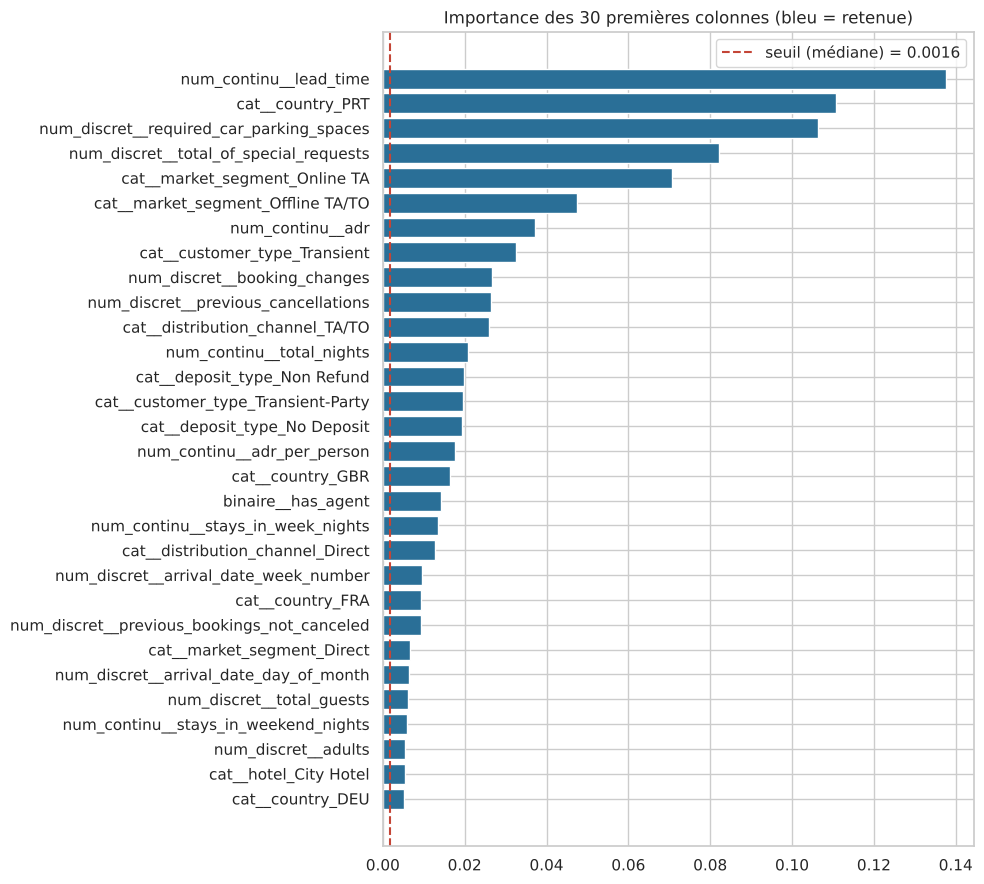

In [32]:
fig, ax = plt.subplots(figsize=(10, 9))
top = bilan.head(30).iloc[::-1]  # 30 premières, la plus importante en haut
ax.barh(top["variable"], top["importance"], color=np.where(top["retenue"], "#2a6f97", "#bbbbbb"))
ax.axvline(selecteur_appris.threshold_, color="#c44536", ls="--",
           label=f"seuil (médiane) = {selecteur_appris.threshold_:.4f}")
ax.set_title("Importance des 30 premières colonnes (bleu = retenue)")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "selection_importances.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
print("Colonnes retenues :")
print(bilan.loc[bilan["retenue"], "variable"].tolist())
print("\nColonnes éliminées :")
print(bilan.loc[~bilan["retenue"], "variable"].tolist())

Colonnes retenues :
['num_continu__lead_time', 'cat__country_PRT', 'num_discret__required_car_parking_spaces', 'num_discret__total_of_special_requests', 'cat__market_segment_Online TA', 'cat__market_segment_Offline TA/TO', 'num_continu__adr', 'cat__customer_type_Transient', 'num_discret__booking_changes', 'num_discret__previous_cancellations', 'cat__distribution_channel_TA/TO', 'num_continu__total_nights', 'cat__deposit_type_Non Refund', 'cat__customer_type_Transient-Party', 'cat__deposit_type_No Deposit', 'num_continu__adr_per_person', 'cat__country_GBR', 'binaire__has_agent', 'num_continu__stays_in_week_nights', 'cat__distribution_channel_Direct', 'num_discret__arrival_date_week_number', 'cat__country_FRA', 'num_discret__previous_bookings_not_canceled', 'cat__market_segment_Direct', 'num_discret__arrival_date_day_of_month', 'num_discret__total_guests', 'num_continu__stays_in_weekend_nights', 'num_discret__adults', 'cat__hotel_City Hotel', 'cat__country_DEU', 'binaire__has_company', '

### Bilan par variable d'origine

In [34]:
summarize_by_original_variable(bilan, colonnes_cat).round(4)

,importance_totale,colonnes,colonnes_retenues,statut
variable_origine,,,,
country,0.1548,22,7,partiellement retenue
lead_time,0.1376,1,1,retenue
market_segment,0.1322,7,5,partiellement retenue
required_car_parking_spaces,0.1063,1,1,retenue
total_of_special_requests,0.0823,1,1,retenue
customer_type,0.0564,4,3,partiellement retenue
distribution_channel,0.0415,4,3,partiellement retenue
deposit_type,0.0395,3,2,partiellement retenue
adr,0.0372,1,1,retenue


### Contrôle par l'information mutuelle (méthode indépendante du modèle)

In [35]:
X_train_prep_sel = pd.DataFrame(pipeline_selection.named_steps["preprocessing"].transform(X_train))
mi = mutual_information_ranking(X_train_prep_sel, y_train)
comparaison = bilan.set_index("variable").join(mi)
rho = comparaison["importance"].corr(comparaison["information_mutuelle"], method="spearman")
communes = set(bilan.head(15)["variable"]) & set(mi.head(15).index)
print(f"Corrélation de rang (Spearman) entre les deux classements : {rho:.2f}")
print(f"Colonnes communes aux 15 premières des deux méthodes : {len(communes)} / 15")
mi.head(15).round(4).to_frame()

Corrélation de rang (Spearman) entre les deux classements : 0.58
Colonnes communes aux 15 premières des deux méthodes : 11 / 15


,information_mutuelle
num_continu__lead_time,0.0381
num_continu__adr,0.0362
num_discret__required_car_parking_spaces,0.0300
num_continu__adr_per_person,0.0240
cat__market_segment_Online TA,0.0236
binaire__has_agent,0.0205
cat__customer_type_Transient,0.0149
cat__deposit_type_Non Refund,0.0141
cat__distribution_channel_TA/TO,0.0119
cat__deposit_type_No Deposit,0.0119


## 4.4 Intégration dans le pipeline et effet sur les performances
On compare en validation croisée (5 plis, entraînement seulement) le même pipeline **avec** et **sans** l'étape de sélection. Le critère est le **F2 maximal** (défini en Partie 5.1).

In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

from src.evaluation import best_f2_scorer

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)

avec_selection = copie(model_pipeline)                    # prétraitement -> sélection -> modèle
sans_selection = Pipeline([                               # prétraitement -> modèle
    ("preprocessing", copie(pipeline_pretraitement)),
    ("model", copie(model_pipeline.named_steps["model"])),
])
f2_avec = cross_val_score(avec_selection, X_train, y_train, cv=cv5, scoring=best_f2_scorer)
f2_sans = cross_val_score(sans_selection, X_train, y_train, cv=cv5, scoring=best_f2_scorer)

pd.DataFrame(
    {"colonnes": [bilan["retenue"].sum(), len(bilan)],
     "F2 maximal moyen": [f2_avec.mean(), f2_sans.mean()],
     "écart-type": [f2_avec.std(), f2_sans.std()]},
    index=["avec sélection", "sans sélection"],
).round(4)

,colonnes,F2 maximal moyen,écart-type
avec sélection,47,0.7885,0.0020
sans sélection,93,0.7889,0.0028


**Interprétation :**

- **Retenues (47 colonnes sur 93)** : `lead_time`, `country`, `market_segment`, `required_car_parking_spaces`, `total_of_special_requests`, `customer_type`, `deposit_type`, `adr`, `booking_changes`, `previous_cancellations`, et plusieurs variables créées par `HotelFeatureEngineer` (`total_nights`, `adr_per_person`, `has_agent`, `has_company`, `total_guests`) : l'ingénierie des caractéristiques est utile.
- **Éliminées (46 colonnes)** : surtout des indicatrices peu informatives, comme les 12 mois d'arrivée (l'information saisonnière est déjà portée par `arrival_date_week_number` et la saison), la plupart des types de chambre, les pays peu représentés et certaines formules de repas.
- **Contrôle** : 11 des 15 premières colonnes sont communes à la forêt et à l'information mutuelle (corrélation de rang de 0,58). Deux méthodes de nature différente s'accordent sur l'essentiel.
- **Effet sur la performance** : diviser le nombre de colonnes par deux ne change pas le F2 maximal (0,7885 avec sélection, 0,7889 sans), un écart inférieur à l'écart-type entre plis. Le modèle est plus simple et plus rapide, pour une performance équivalente.

---
# Partie 5 : Construction et évaluation du modèle prédictif

## 5.1 Choix de l'algorithme

**Métrique : le F2.** Il combine précision et rappel en donnant **deux fois plus de poids au rappel** : l'hôtel veut détecter le plus d'annulations possible, sans pour autant signaler tout le monde (ce qui ferait chuter la précision, donc le F2). On n'optimise pas directement le rappel : un modèle qui prédit « annulée » pour toutes les réservations aurait un rappel de 100 % et ne servirait à rien.

Le F2 dépend du seuil de décision. Pour comparer les modèles équitablement, on utilise le **F2 maximal** (au meilleur seuil de chaque modèle) : sinon un modèle sans pondération des classes serait pénalisé par le seuil arbitraire de 0,5.

**Cinq configurations** sont comparées **dans le même pipeline** (on remplace seulement l'étape `model` de `model_pipeline`), en validation croisée à 5 plis sur l'entraînement :

| Modèle | Intérêt |
|---|---|
| Régression logistique | référence linéaire, interprétable |
| Forêt aléatoire, avec et sans `class_weight="balanced"` | non linéaire, robuste |
| HistGradientBoosting, avec et sans `class_weight="balanced"` | boosting d'arbres, rapide sur les données tabulaires |

`class_weight="balanced"` donne à chaque annulation un poids environ 2,6 fois plus grand (72 % de réservations maintenues, 28 % d'annulées) : les arbres cherchent davantage à isoler les annulations.

,f2_max,f2_max_écart,pr_auc,pr_auc_écart,roc_auc,roc_auc_écart,precision,precision_écart,recall,recall_écart,temps (s)
modèle,,,,,,,,,,,
Forêt aléatoire (balanced),0.7920,0.0032,0.7570,0.0069,0.8906,0.0026,0.6401,0.0059,0.7687,0.0064,11.2594
Forêt aléatoire,0.7900,0.0029,0.7613,0.0063,0.8899,0.0025,0.7462,0.0068,0.5849,0.0099,11.0080
HistGradientBoosting (balanced),0.7885,0.0020,0.7514,0.0071,0.8863,0.0023,0.5855,0.0050,0.8190,0.0021,5.6368
HistGradientBoosting,0.7880,0.0013,0.7526,0.0059,0.8861,0.0019,0.7224,0.0050,0.6018,0.0049,4.9457
Régression logistique,0.7390,0.0026,0.6534,0.0063,0.8281,0.0038,0.6706,0.0082,0.4425,0.0062,4.3860


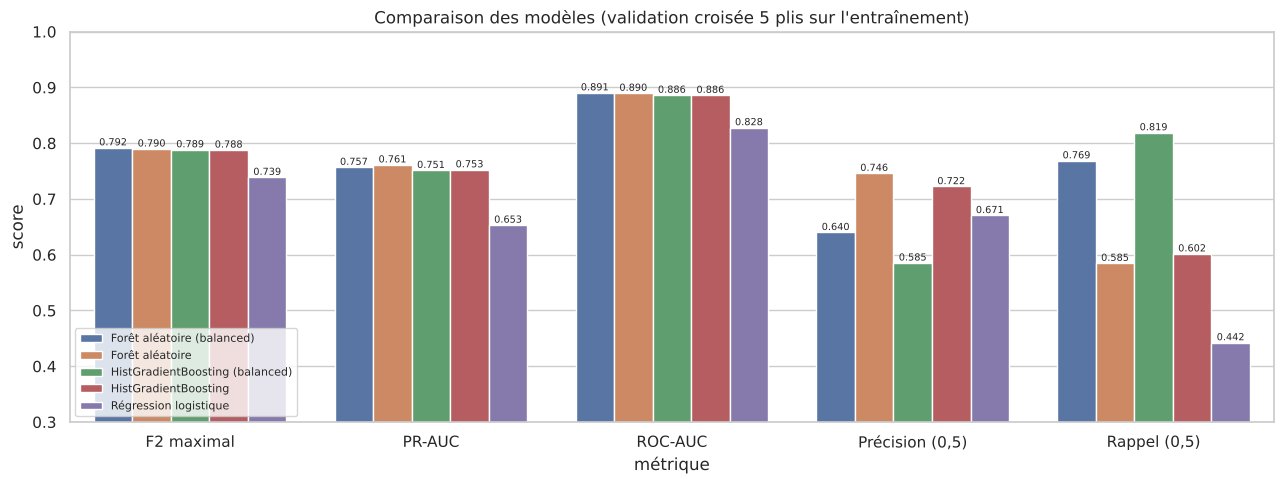

In [37]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

from src.evaluation import plot_model_comparison

RS = config.RANDOM_STATE
modeles = {
    "Régression logistique": LogisticRegression(max_iter=2000, random_state=RS),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RS),
    "Forêt aléatoire (balanced)": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1,
                                                         class_weight="balanced", random_state=RS),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RS),
    "HistGradientBoosting (balanced)": HistGradientBoostingClassifier(class_weight="balanced", random_state=RS),
}
scoring = {
    "f2_max": best_f2_scorer,          # critère principal
    "pr_auc": "average_precision",     # qualité du classement, adaptée au déséquilibre
    "roc_auc": "roc_auc",              # qualité du classement, mesure classique
    "precision": "precision",          # au seuil de 0,5 (pour information)
    "recall": "recall",                # au seuil de 0,5 (pour information)
}

lignes = []
for nom, modele in modeles.items():
    # Même pipeline complet, seule l'étape "model" change
    pipe = copie(model_pipeline).set_params(model=modele)
    scores = cross_validate(pipe, X_train, y_train, cv=cv5, scoring=scoring)
    ligne = {"modèle": nom}
    for m in scoring:
        ligne[m] = scores[f"test_{m}"].mean()
        ligne[f"{m}_écart"] = scores[f"test_{m}"].std()
    ligne["temps (s)"] = scores["fit_time"].mean()
    lignes.append(ligne)

resultats = pd.DataFrame(lignes).set_index("modèle").sort_values("f2_max", ascending=False)
display(resultats.round(4))
plot_model_comparison(resultats)
plt.show()

**Interprétation :**

- La **régression logistique** est nettement en retrait (F2 maximal 0,739) : les relations avec l'annulation ne sont pas linéaires.
- Les quatre modèles à base d'arbres sont **au coude à coude** : F2 maximal entre 0,788 et 0,792, des écarts du même ordre que la variation entre plis (0,001 à 0,003).
- **Effet de `class_weight="balanced"`** : au seuil de 0,5, il fait passer le rappel de 58 % à 77 % (forêt) et de 60 % à 82 % (boosting). Mais le F2 maximal ne bouge presque pas : la pondération **déplace surtout le seuil**, elle n'améliore pas le classement des réservations. Le même gain de rappel s'obtient en abaissant le seuil, ce que fait la Partie 5.3.

Comme aucun modèle ne se détache, le choix final est confié à l'optimisation des hyperparamètres, qui explore les deux familles avec le même budget.

## 5.2 Pipeline complet et optimisation des hyperparamètres
Le pipeline complet est `model_pipeline` (fin de `src/pipelines.py`, cours : « Pipeline complet : Prétraitement & Modèle d'apprentissage ») :

In [38]:
afficher_code("# 5. Pipeline complet")

# ----- Extrait de src/pipelines.py -----
# 5. Pipeline complet : prétraitement + sélection + modèle (Partie 5)
#    Le modèle indiqué ici est celui retenu à l'issue de la comparaison du
#    notebook (HistGradientBoosting avec pondération des classes). Le notebook
#    remplace l'étape "model" par d'autres algorithmes pour les comparer :
#        clone(model_pipeline).set_params(model=RandomForestClassifier(...))
# ===========================================================================
model_pipeline = Pipeline([
    ("preprocessing", pipeline_pretraitement),  # Parties 2 et 3
    ("selection", selecteur),                   # Partie 4
    ("model", HistGradientBoostingClassifier(   # Partie 5
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])


In [39]:
model_pipeline  # 3 étapes : preprocessing -> selection -> model

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('creation_variables', HotelFeatureEngineer()),
                                 ('colonnes',
                                  ColumnTransformer(transformers=[('num_continu',
                                                                   Pipeline(steps=[('imputation',
                                                                                    SimpleImputer(strategy='median')),
                                                                                   ('ecretage',
                                                                                    OutlierCapper()),
                                                                                   ('scaling',
                                                                                    StandardScaler())]),
                                                                   ['lead_time',
                                                             

**Optimisation.** `RandomizedSearchCV` explore 16 combinaisons tirées dans un espace qui couvre **les deux familles** (forêt et HistGradientBoosting), avec et sans pondération des classes. L'étape `model` du pipeline est elle-même un hyperparamètre. Critère : F2 maximal ; validation croisée à 3 plis (coût de calcul). Comme prétraitement et sélection sont dans le pipeline, ils sont réappris sur chaque pli : aucune information de validation ne fuit.

In [40]:
from typing import cast

from sklearn.model_selection import RandomizedSearchCV

espace = [
    {   # famille 1 : forêt aléatoire
        "model": [RandomForestClassifier(n_jobs=-1, random_state=RS)],
        "model__n_estimators": [200, 300],
        "model__max_depth": [None, 20, 30],         # None = arbres complets
        "model__min_samples_leaf": [1, 2, 5],       # taille minimale d'une feuille
        "model__max_features": ["sqrt", 0.3],       # variables tirées à chaque nœud
        "model__class_weight": [None, "balanced"],
    },
    {   # famille 2 : HistGradientBoosting
        "model": [HistGradientBoostingClassifier(random_state=RS)],
        "model__learning_rate": [0.03, 0.05, 0.1],  # pas d'apprentissage
        "model__max_iter": [300, 600],              # nombre d'arbres successifs
        "model__max_leaf_nodes": [31, 63, 127],     # complexité de chaque arbre
        "model__min_samples_leaf": [20, 50],
        "model__l2_regularization": [0.0, 0.1, 1.0],  # pénalité contre le surapprentissage
        "model__class_weight": [None, "balanced"],
    },
]
recherche = RandomizedSearchCV(
    copie(model_pipeline),
    param_distributions=espace,
    n_iter=16,
    scoring=best_f2_scorer,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RS),
    random_state=RS,
    refit=True,  # réentraîne la meilleure combinaison sur tout l'entraînement
)
recherche.fit(X_train, y_train)

meilleur_pipeline = cast(Pipeline, recherche.best_estimator_)
print(f"Meilleur F2 maximal en validation croisée : {recherche.best_score_:.4f}")
print("Meilleure combinaison :")
for k, v in recherche.best_params_.items():
    print(f"  {k:<28} = {v}")

Meilleur F2 maximal en validation croisée : 0.7918
Meilleure combinaison :
  model__min_samples_leaf      = 20
  model__max_leaf_nodes        = 127
  model__max_iter              = 300
  model__learning_rate         = 0.03
  model__l2_regularization     = 1.0
  model__class_weight          = balanced
  model                        = HistGradientBoostingClassifier(random_state=42)


In [41]:
# Les 8 meilleures combinaisons
res = pd.DataFrame(recherche.cv_results_)
res["famille"] = res["param_model"].map(lambda m: type(m).__name__)
cols = ["famille", "param_model__class_weight", "mean_test_score", "std_test_score", "mean_fit_time"]
res.sort_values("rank_test_score")[cols].head(8).round(4)

,famille,param_model__class_weight,mean_test_score,std_test_score,mean_fit_time
2,HistGradientBoostingClassifier,balanced,0.7918,0.0019,9.5729
8,HistGradientBoostingClassifier,NaN,0.7910,0.0019,8.3256
6,RandomForestClassifier,balanced,0.7905,0.0013,11.6408
13,HistGradientBoostingClassifier,balanced,0.7904,0.0020,5.6382
9,HistGradientBoostingClassifier,balanced,0.7898,0.0028,6.8366
7,HistGradientBoostingClassifier,NaN,0.7897,0.0006,5.0274
12,HistGradientBoostingClassifier,NaN,0.7896,0.0024,7.3234
0,RandomForestClassifier,balanced,0.7891,0.0023,18.3665


**Interprétation :** la meilleure combinaison est un **HistGradientBoosting avec `class_weight="balanced"`** (F2 maximal 0,7918), devant la meilleure forêt (0,7905). L'écart reste faible : les deux familles sont aussi performantes sur ces données. HistGradientBoosting est retenu car il est aussi le plus rapide à entraîner (8 secondes contre 11 à 16 pour la forêt) et produit un modèle beaucoup plus léger, ce qui compte pour l'application Streamlit.

## 5.3 Entraînement et évaluation

### Étape 1 : calibration des probabilités
`class_weight="balanced"` gonfle les probabilités prédites (le modèle « croit » qu'il y a autant d'annulations que de maintiens). Or l'analyse prescriptive utilise directement ces probabilités (perte espérée, surréservation). On remplace donc l'étape `model` par le même modèle enveloppé dans `CalibratedClassifierCV` (calibration isotonique, 3 plis), qui ramène les probabilités à des fréquences réelles sans changer l'ordre des réservations.

### Étape 2 : choix des seuils de décision dans l'entraînement
Les probabilités hors pli (validation croisée à 5 plis sur l'entraînement) servent à choisir deux seuils, sans regarder le test :
- **seuil F2** : maximise le F2 (rappel prioritaire) ; c'est le seuil de décision du modèle ;
- **seuil F0,5** : maximise le F0,5 (précision prioritaire) ; utilisé par l'analyse prescriptive pour les actions contraignantes.

### Étape 3 : modèle final
`FixedThresholdClassifier` intègre le seuil F2 au pipeline : `predict()` applique directement ce seuil.

Seuil F2   (rappel prioritaire)    : 0.171
Seuil F0,5 (précision prioritaire) : 0.537


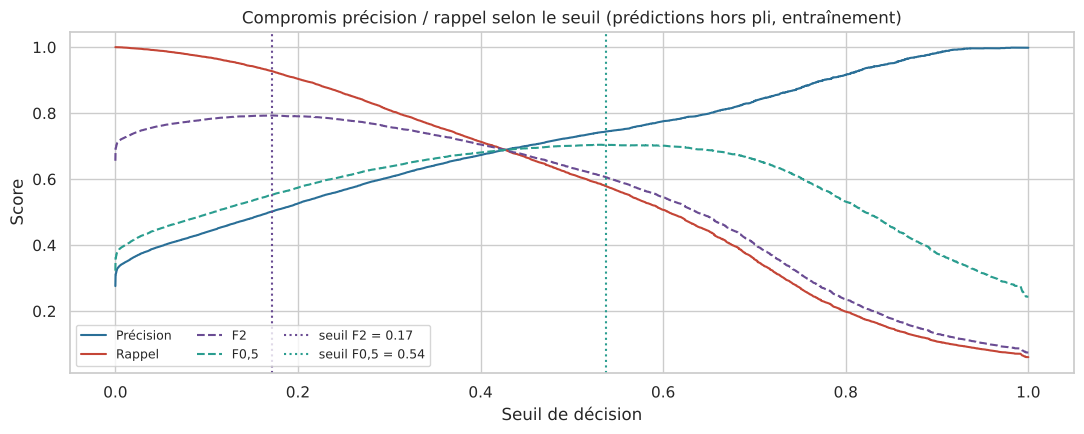

In [42]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import FixedThresholdClassifier, cross_val_predict

from src.evaluation import plot_thresholds
from src.prescriptive import best_threshold, fbeta_by_threshold

# Étape 1 : même pipeline, étape "model" calibrée
modele_retenu = copie(meilleur_pipeline.named_steps["model"])
pipeline_calibre = copie(meilleur_pipeline).set_params(
    model=CalibratedClassifierCV(modele_retenu, method="isotonic", cv=3)
)

# Étape 2 : probabilités hors pli sur l'entraînement, puis seuils F2 et F0,5
proba_oof = np.asarray(cross_val_predict(pipeline_calibre, X_train, y_train, cv=cv5, method="predict_proba"))[:, 1]
seuil_f2 = best_threshold(y_train, proba_oof, beta=2)
seuil_f05 = best_threshold(y_train, proba_oof, beta=0.5)
print(f"Seuil F2   (rappel prioritaire)    : {seuil_f2:.3f}")
print(f"Seuil F0,5 (précision prioritaire) : {seuil_f05:.3f}")

plot_thresholds(fbeta_by_threshold(y_train, proba_oof), seuil_f2, seuil_f05)
plt.show()

In [43]:
# Étape 3 : modèle final = pipeline calibré + seuil F2, entraîné sur tout l'entraînement
modele_final = FixedThresholdClassifier(pipeline_calibre).set_params(threshold=seuil_f2)
modele_final.fit(X_train, y_train)          # cours : model_pipeline.fit(X_train, y_train)

y_pred = modele_final.predict(X_test)       # cours : y_pred = model_pipeline.predict(X_test)
proba_test = modele_final.predict_proba(X_test)[:, 1]

### Évaluation finale sur l'ensemble de test

In [44]:
from src.evaluation import compute_metrics, plot_evaluation, report_table

metriques = pd.DataFrame(
    [compute_metrics(y_test, proba_test, seuil_f2),
     compute_metrics(y_test, proba_test, seuil_f05),
     compute_metrics(y_test, proba_test, 0.5)],
    index=[f"seuil F2 ({seuil_f2:.2f})", f"seuil F0,5 ({seuil_f05:.2f})", "seuil 0,50"],
)
metriques.round(4)

,seuil,accuracy,precision,recall,f1,f2,roc_auc,pr_auc
seuil F2 (0.17),0.1710,0.7319,0.5076,0.9311,0.6570,0.7979,0.8949,0.7668
"seuil F0,5 (0.54)",0.5374,0.8318,0.7493,0.5865,0.6580,0.6132,0.8949,0.7668
"seuil 0,50",0.5000,0.8322,0.7327,0.6167,0.6697,0.6369,0.8949,0.7668


In [45]:
print(f"Rapport de classification au seuil F2 ({seuil_f2:.2f}) :")
report_table(y_test, y_pred)

Rapport de classification au seuil F2 (0.17) :


,precision,recall,f1-score,support
Maintenue (0),0.962,0.656,0.780,12454.000
Annulée (1),0.508,0.931,0.657,4743.000
accuracy,0.732,0.732,0.732,0.732
macro avg,0.735,0.794,0.718,17197.000
weighted avg,0.836,0.732,0.746,17197.000


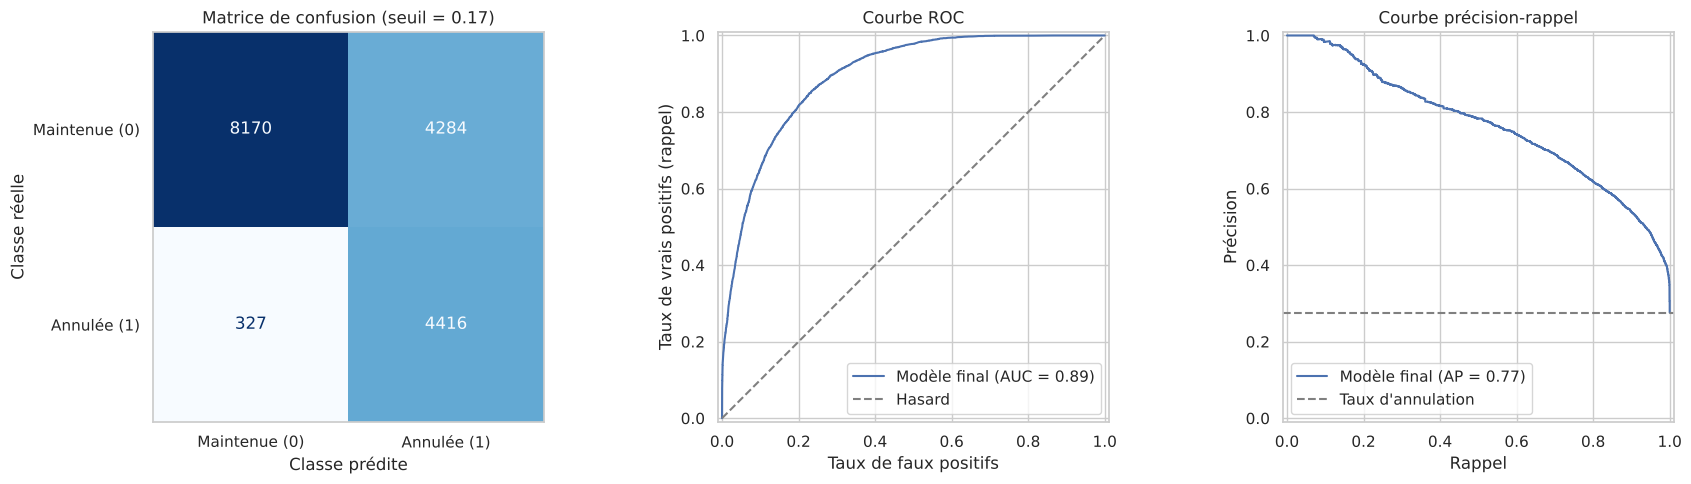

In [46]:
plot_evaluation(y_test, proba_test, threshold=seuil_f2, model_name="Modèle final")
plt.show()

In [47]:
from sklearn.metrics import brier_score_loss, roc_auc_score

# Surapprentissage : comparaison entraînement / validation croisée / test
auc_train = roc_auc_score(y_train, modele_final.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, proba_test)
print(f"ROC-AUC entraînement : {auc_train:.4f} | test : {auc_test:.4f}")
print(f"F2 maximal : validation croisée {recherche.best_score_:.4f} | test {best_f2_scorer(modele_final, X_test, y_test):.4f}")

ROC-AUC entraînement : 0.9309 | test : 0.8949


F2 maximal : validation croisée 0.7918 | test 0.7980


### Effet de la calibration

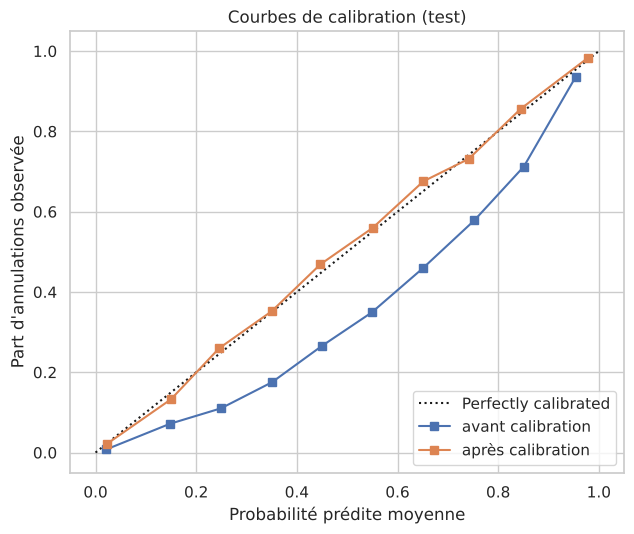

Score de Brier (plus bas = meilleur) : avant 0.1308 | après 0.1153 | sans modèle 0.1997


In [48]:
from sklearn.calibration import CalibrationDisplay

proba_non_calibree = meilleur_pipeline.predict_proba(X_test)[:, 1]  # avant calibration

fig, ax = plt.subplots(figsize=(6.5, 5.5))
CalibrationDisplay.from_predictions(y_test, proba_non_calibree, n_bins=10, name="avant calibration", ax=ax)
CalibrationDisplay.from_predictions(y_test, proba_test, n_bins=10, name="après calibration", ax=ax)
ax.set_title("Courbes de calibration (test)")
ax.set_xlabel("Probabilité prédite moyenne")
ax.set_ylabel("Part d'annulations observée")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "calibration.png", dpi=150, bbox_inches="tight")
plt.show()

reference = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))
print(f"Score de Brier (plus bas = meilleur) : avant {brier_score_loss(y_test, proba_non_calibree):.4f} | "
      f"après {brier_score_loss(y_test, proba_test):.4f} | sans modèle {reference:.4f}")

### Quelles variables pilotent la prédiction ?

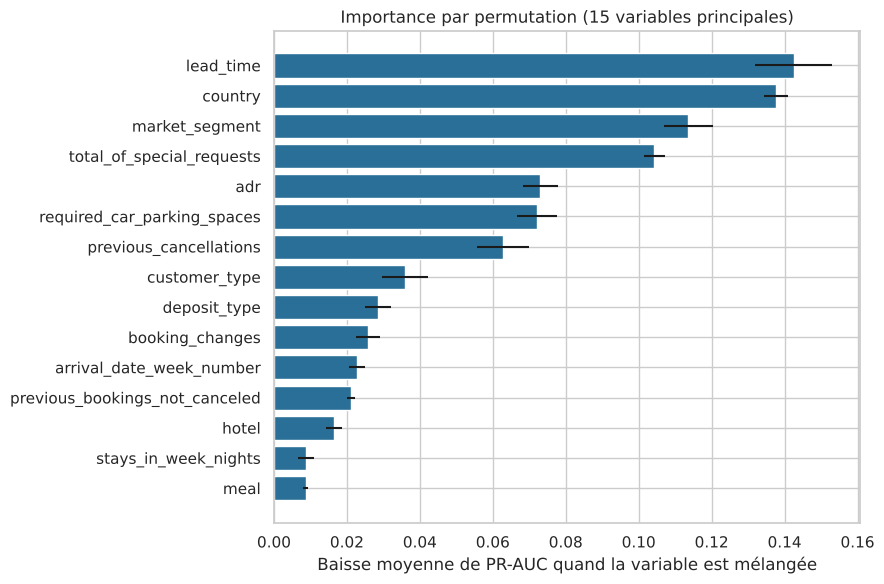

,variable,baisse_pr_auc,écart
0,lead_time,0.1425,0.0106
1,country,0.1377,0.0032
2,market_segment,0.1136,0.0068
3,total_of_special_requests,0.1042,0.0029
4,adr,0.0730,0.0048
5,required_car_parking_spaces,0.0722,0.0054
6,previous_cancellations,0.0628,0.0072
7,customer_type,0.0359,0.0063
8,deposit_type,0.0285,0.0037
9,booking_changes,0.0257,0.0033


In [49]:
from src.evaluation import permutation_importance_table, plot_permutation_importance

# On mélange une variable BRUTE à la fois et on mesure la baisse de PR-AUC du modèle complet
importance = permutation_importance_table(modele_final, X_test, y_test, n_samples=5000, n_repeats=5)
plot_permutation_importance(importance, top=15)
plt.show()
importance.head(10).round(4)

**Interprétation des résultats sur le test (17 197 réservations jamais vues) :**

- **Généralisation** : F2 maximal de 0,798 sur le test, contre 0,792 en validation croisée ; ROC-AUC de 0,895. Le modèle généralise bien. L'écart avec l'entraînement (ROC-AUC 0,931) traduit un léger surapprentissage sans conséquence.
- **Au seuil F2 (0,17)** : le modèle détecte **93 % des annulations** (rappel), et environ une alerte sur deux est une vraie annulation (précision 51 %). C'est le seuil adapté à une action **sans engagement** (un rappel), qui ne coûte rien même quand l'alerte est fausse.
- **Au seuil F0,5 (0,54)** : **75 % des alertes sont de vraies annulations**, pour 59 % des annulations détectées. C'est le seuil adapté à une action **contraignante** (un acompte), où il faut limiter le nombre de clients fidèles visés à tort.
- **Calibration** : le score de Brier passe de 0,131 à 0,115 (0,200 sans modèle) et la courbe se rapproche de la diagonale. Les probabilités sont fiables, ce qui permet de les utiliser dans l'analyse prescriptive.
- **Variables déterminantes** : délai de réservation, pays, segment de marché, demandes spéciales, tarif, places de stationnement et annulations passées.

**Point de vigilance :** une demande de place de stationnement s'accompagne de 0 % d'annulation, et le Portugal concentre une part anormale d'annulations. Ces informations pourraient être complétées à l'arrivée du client (fuite partielle) : à vérifier auprès de l'hôtel avant une mise en production.

### Accéder aux étapes du pipeline entraîné (cours : « Accéder aux étapes internes d'un Pipeline »)

In [50]:
pipeline_entraine = cast(Pipeline, modele_final.estimator_)  # le pipeline calibré, entraîné

print("Par index    : model_pipeline.steps[0] ->", pipeline_entraine.steps[0][0])
print("Par nom      : model_pipeline.named_steps['model'] ->", pipeline_entraine.named_steps["model"])

# Visualisation des données transformées (cours : « Visualisation des données transformées »)
X_transformed = pipeline_entraine.named_steps["preprocessing"].transform(X_train)
pd.DataFrame(X_transformed).head()

Par index    : model_pipeline.steps[0] -> preprocessing
Par nom      : model_pipeline.named_steps['model'] -> CalibratedClassifierCV(cv=3,
                       estimator=HistGradientBoostingClassifier(class_weight='balanced',
                                                                l2_regularization=1.0,
                                                                learning_rate=0.03,
                                                                max_iter=300,
                                                                max_leaf_nodes=127,
                                                                random_state=42),
                       method='isotonic')


,num_continu__lead_time,num_continu__adr,num_continu__stays_in_weekend_nights,num_continu__stays_in_week_nights,num_continu__total_nights,num_continu__adr_per_person,num_discret__days_in_waiting_list,num_discret__arrival_date_week_number,num_discret__arrival_date_day_of_month,num_discret__adults,num_discret__children,num_discret__babies,num_discret__previous_cancellations,num_discret__previous_bookings_not_canceled,num_discret__booking_changes,num_discret__required_car_parking_spaces,num_discret__total_of_special_requests,num_discret__total_guests,binaire__is_repeated_guest,binaire__has_children,binaire__has_agent,binaire__has_company,cat__hotel_City Hotel,cat__hotel_Resort Hotel,cat__arrival_date_month_April,cat__arrival_date_month_August,cat__arrival_date_month_December,cat__arrival_date_month_February,cat__arrival_date_month_January,cat__arrival_date_month_July,...,cat__market_segment_Complementary,cat__market_segment_Corporate,cat__market_segment_Direct,cat__market_segment_Groups,cat__market_segment_Offline TA/TO,cat__market_segment_Online TA,cat__distribution_channel_Autre,cat__distribution_channel_Corporate,cat__distribution_channel_Direct,cat__distribution_channel_TA/TO,cat__reserved_room_type_A,cat__reserved_room_type_Autre,cat__reserved_room_type_B,cat__reserved_room_type_C,cat__reserved_room_type_D,cat__reserved_room_type_E,cat__reserved_room_type_F,cat__reserved_room_type_G,cat__reserved_room_type_H,cat__deposit_type_Autre,cat__deposit_type_No Deposit,cat__deposit_type_Non Refund,cat__customer_type_Contract,cat__customer_type_Group,cat__customer_type_Transient,cat__customer_type_Transient-Party,cat__arrival_season_Automne,cat__arrival_season_Ete,cat__arrival_season_Hiver,cat__arrival_season_Printemps
74199,-0.896850,-0.968723,-0.000222,-0.319397,-0.242621,0.063912,-0.070392,-1.667095,1.265108,-1.400601,-0.305112,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,-0.846662,-1.294837,0,0,1,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
17309,-0.944978,-1.244588,-0.000222,-1.374035,-1.034153,-0.452993,-0.070392,-1.082124,-0.203910,-1.400601,-0.305112,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,-0.846662,-1.294837,0,0,1,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
17689,-0.668243,-0.950280,1.016470,0.207923,0.548912,-0.967692,-0.070392,-1.082124,0.361097,0.188177,-0.305112,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,0.353768,-0.040660,0,0,1,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
59540,-0.078679,-0.137009,-1.016913,0.735242,0.153145,-0.205753,-0.070392,-0.789639,-0.429913,0.188177,-0.305112,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,0.353768,-0.040660,0,0,1,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
32606,0.919971,3.062433,1.016470,1.262561,1.340444,0.429349,-0.070392,0.307181,1.717114,0.188177,4.060846,-0.094861,-0.083642,-0.110026,-0.380418,-0.299926,2.754629,2.467692,0,1,1,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


### Sauvegarde et prédiction sur une nouvelle réservation
Le pipeline complet est sauvegardé (`src/sauvegarde.py`). Il est réutilisé par `02_analyse_prescriptive.ipynb` et par l'application Streamlit. Il accepte directement une réservation **brute** : tout le prétraitement est appliqué automatiquement.

In [51]:
from src.sauvegarde import load_pipeline, save_artifacts

metadata = {
    "modele": type(modele_retenu).__name__,
    "hyperparametres": {k: str(v) for k, v in recherche.best_params_.items() if k != "model"},
    "calibration": "CalibratedClassifierCV isotonique, 3 plis",
    "seuil_f2": seuil_f2,
    "seuil_f05": seuil_f05,
    "n_entrainement": int(len(X_train)),
    "n_test": int(len(X_test)),
    "taux_annulation": float(y.mean()),
    "metriques_test_seuil_f2": compute_metrics(y_test, proba_test, seuil_f2),
    "metriques_test_seuil_f05": compute_metrics(y_test, proba_test, seuil_f05),
    "pays": sorted(X_train["country"].dropna().unique().tolist()),
}
# L'année d'arrivée est jointe à l'ensemble de test pour l'analyse prescriptive (dates réelles)
test_avec_annee = X_test.assign(arrival_date_year=df.loc[X_test.index, "arrival_date_year"].values)
save_artifacts(modele_final, metadata, test_avec_annee, y_test)
print(f"Pipeline sauvegardé : {config.MODEL_PATH.relative_to(config.ROOT_DIR)}")

Pipeline sauvegardé : models/pipeline_annulation.joblib


In [52]:
modele_charge = load_pipeline()

nouvelle = pd.DataFrame([{
    "hotel": "City Hotel", "lead_time": 210, "arrival_date_month": "August", "arrival_date_week_number": 33,
    "arrival_date_day_of_month": 14, "stays_in_weekend_nights": 2, "stays_in_week_nights": 3, "adults": 2,
    "children": 0, "babies": 0, "meal": "BB", "country": "PRT", "market_segment": "Online TA",
    "distribution_channel": "TA/TO", "is_repeated_guest": 0, "previous_cancellations": 0,
    "previous_bookings_not_canceled": 0, "reserved_room_type": "A", "booking_changes": 0,
    "deposit_type": "No Deposit", "agent": 9.0, "company": np.nan, "days_in_waiting_list": 0,
    "customer_type": "Transient", "adr": 135.0, "required_car_parking_spaces": 0, "total_of_special_requests": 0,
}])
p = modele_charge.predict_proba(nouvelle)[0, 1]
decision = modele_charge.predict(nouvelle)[0]
print(f"Probabilité d'annulation : {p:.1%}")
print(f"Décision au seuil F2 ({seuil_f2:.2f}) : {'annulation probable' if decision == 1 else 'réservation probablement maintenue'}")

Probabilité d'annulation : 81.2%
Décision au seuil F2 (0.17) : annulation probable


---
# Conclusion

| Étape | Réalisation | Résultat clé |
|---|---|---|
| Exploration | diagnostic de qualité, détection de la fuite de données | 3 colonnes de fuite exclues, 33 241 doublons supprimés |
| Prétraitement | 4 sous-pipelines réunis par un `ColumnTransformer` (`src/pipelines.py`) | 27 variables brutes, 93 colonnes, 0 valeur manquante |
| Transformateurs | `HotelFeatureEngineer`, `RareCategoryGrouper`, `OutlierCapper` (`src/transformers.py`) | 7 variables créées, `country` réduit de 168 à 21 modalités |
| Sélection | `SelectFromModel` (forêt aléatoire, seuil médian) | 47 colonnes sur 93, performance inchangée |
| Modèle | 5 configurations comparées sur le F2, optimisation, calibration, seuils choisis dans l'entraînement | 93 % des annulations détectées au seuil F2 ; 75 % d'alertes justes au seuil F0,5 |

**Apport du pipeline.** Toutes les étapes, de la création de variables au modèle, forment un seul objet : il s'entraîne en une ligne (`fit`), s'évalue en validation croisée sans fuite, se sauvegarde, puis prédit directement sur une réservation brute (`predict`). Le même objet est réutilisé tel quel par l'analyse prescriptive et l'application Streamlit.

**Limites.**
- Deux hôtels portugais entre 2015 et 2017 : il faut réentraîner le modèle avant de l'appliquer ailleurs.
- Une validation temporelle (entraîner sur 2015 et 2016, tester sur 2017) serait plus réaliste qu'une séparation aléatoire.
- `required_car_parking_spaces` et `country` sont à vérifier auprès de l'hôtel (risque de fuite partielle).

**Suite.** Le notebook `02_analyse_prescriptive.ipynb` utilise ce pipeline pour chiffrer le coût des annulations et ce qu'un acompte permettrait de récupérer.